# 05 · Pattern Analysis & Graph Feature Extraction
Goal: let **Cypher queries find behavioural evidence in the graph** ("late 4 months in a row", "recovered, then late again") and turn that evidence into features.

How we keep it honest:
* The graph does **not** contain the default label. Queries only see behaviour.
* After a query returns its customers, **Python** looks up how many of them actually defaulted. That is the validation.
* Every graph feature is re-computed in pandas and must match exactly (parity test).

**Setup and connection.**

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from credit_kg import config as C
import seaborn as sns
from credit_kg import data as D, features as F, graph as G, graph_features as GF, stats as S
driver = G.get_driver()
PQ = C.QUERIES / "patterns"
wide, monthly, split = D.load_processed()
labels = wide[["customer_id", C.TARGET]].merge(split)   # the target lives here, outside the graph
base_rate = labels.loc[labels.split == "train", C.TARGET].mean()

**Validation helper.** Given the customers a query returned, compute their real default rate (train and test separately, with 95% confidence intervals) and the *lift* compared with the overall rate.

In [2]:
validation_rows = []
def validate(name, found):
    m = labels.customer_id.isin(found.customer_id)
    row = {"pattern": name, "customers": int(m.sum())}
    for part in ["train", "test"]:
        sub = labels[(labels.split == part) & m]
        lo, hi = S.wilson_ci(sub[C.TARGET].sum(), len(sub))
        row[f"{part}_default_rate"] = round(sub[C.TARGET].mean(), 3)
        row[f"{part}_ci"] = f"[{lo:.3f}, {hi:.3f}]"
    row["lift_vs_base"] = round(row["train_default_rate"] / base_rate, 2)
    validation_rows.append(row)
    return pd.Series(row)

def show(found, n=3):
    return found.head(n)[["customer_id", "evidence"]].style.hide(axis="index")

**Q1 · Repeated delinquency.** Follow each customer's monthly records to their `RepaymentState` node and count the months that are late (3 or more).

In [3]:
q1 = G.run_file(driver, PQ / "Q01_repeated_delinquency.cypher", min_late=3)
display(show(q1)); validate("Q1 late in >=3 of 6 months", q1)

customer_id,evidence
29788,"3 of 6 months late (2005-04, 2005-08, 2005-09)"
29856,"3 of 6 months late (2005-04, 2005-08, 2005-09)"
29682,"3 of 6 months late (2005-04, 2005-07, 2005-08)"


pattern               Q1 late in >=3 of 6 months
customers                                   3744
train_default_rate                         0.599
train_ci                          [0.581, 0.616]
test_default_rate                          0.603
test_ci                           [0.568, 0.638]
lift_vs_base                                2.71
dtype: object

**Q2 · Consecutive late streak.** Walk along the `NEXT_MONTH` chain and find the longest run where every month is late (3 or more in a row). This uses the *order* of months, not just a count.

In [4]:
q2 = G.run_file(driver, PQ / "Q02_late_streak.cypher", min_streak=3)
display(show(q2)); validate("Q2 late >=3 months in a row", q2)

customer_id,evidence
63,late 6 months in a row (2005-04 to 2005-09)
72,late 6 months in a row (2005-04 to 2005-09)
91,late 6 months in a row (2005-04 to 2005-09)


pattern               Q2 late >=3 months in a row
customers                                    3297
train_default_rate                          0.604
train_ci                           [0.585, 0.623]
test_default_rate                           0.604
test_ci                            [0.567, 0.641]
lift_vs_base                                 2.73
dtype: object

**Q3 · High utilization.** Months where the bill used 90% or more of the limit, in at least 3 of 6 months.

In [5]:
q3 = G.run_file(driver, PQ / "Q03_high_utilization.cypher", high_util=C.HIGH_UTIL, min_months=3)
display(show(q3)); validate("Q3 utilization >=90% in >=3 months", q3)

customer_id,evidence
4,utilization >= 90% in 3 of 6 months (peak 98%)
6,utilization >= 90% in 3 of 6 months (peak 128%)
7,utilization >= 90% in 3 of 6 months (peak 108%)


pattern               Q3 utilization >=90% in >=3 months
customers                                           5062
train_default_rate                                 0.305
train_ci                                  [0.291, 0.319]
test_default_rate                                  0.285
test_ci                                   [0.258, 0.313]
lift_vs_base                                        1.38
dtype: object

**Q4 · Rising utilization.** Consecutive `NEXT_MONTH` edges where utilization went up by more than 5 points, 3 or more months running. Notebook 03 predicted this would **not** be a risk signal, so let's see.

In [6]:
q4 = G.run_file(driver, PQ / "Q04_rising_utilization.cypher", rise=C.UTIL_RISE, min_rises=3)
display(show(q4)); validate("Q4 utilization rose >=3 months running", q4)

customer_id,evidence
168,utilization rose 5 months running (2005-04 to 2005-09)
456,utilization rose 5 months running (2005-04 to 2005-09)
1038,utilization rose 5 months running (2005-04 to 2005-09)


pattern               Q4 utilization rose >=3 months running
customers                                               1300
train_default_rate                                     0.193
train_ci                                      [0.170, 0.218]
test_default_rate                                      0.225
test_ci                                       [0.178, 0.281]
lift_vs_base                                            0.87
dtype: object

**Q5 · Improving repayment.** Late in Apr–Jun, a late → not-late step, and clean in Jul–Sep.

In [7]:
q5 = G.run_file(driver, PQ / "Q05_improving_repayment.cypher")
display(show(q5)); validate("Q5 recovered and clean in last 3 months", q5)

customer_id,evidence
12,"late 1x in Apr-Jun, recovered in 2005-05, clean since"
45,"late 1x in Apr-Jun, recovered in 2005-07, clean since"
66,"late 2x in Apr-Jun, recovered in 2005-06, clean since"


pattern               Q5 recovered and clean in last 3 months
customers                                                1629
train_default_rate                                      0.235
train_ci                                       [0.213, 0.259]
test_default_rate                                       0.184
test_ci                                        [0.146, 0.230]
lift_vs_base                                             1.06
dtype: object

**Q6 · Weak payment coverage.** Read the `coverage` stored on each `NEXT_MONTH` edge: the payment paid less than 10% of the previous statement, in 3 or more months.

In [8]:
q6 = G.run_file(driver, PQ / "Q06_weak_coverage.cypher", weak=C.WEAK_COVERAGE, min_edges=3)
display(show(q6)); validate("Q6 paid <10% of statement in >=3 months", q6)

customer_id,evidence
3,paid < 10% of the previous statement in 3 of 5 months with a bill due
4,paid < 10% of the previous statement in 5 of 5 months with a bill due
6,paid < 10% of the previous statement in 5 of 5 months with a bill due


pattern               Q6 paid <10% of statement in >=3 months
customers                                               15433
train_default_rate                                      0.267
train_ci                                       [0.259, 0.275]
test_default_rate                                       0.261
test_ci                                        [0.246, 0.277]
lift_vs_base                                             1.21
dtype: object

**Q7 · Stable full payer.** Every statement that was due was paid in full the next month (at least 3 times), and the customer was never late.

In [9]:
q7 = G.run_file(driver, PQ / "Q07_stable_payer.cypher", full=C.FULL_COVERAGE, min_edges=3)
display(show(q7)); validate("Q7 always paid in full, never late", q7)

customer_id,evidence
22,"paid the previous statement in full in all 4 months with a bill due, never late"
24,"paid the previous statement in full in all 3 months with a bill due, never late"
29,"paid the previous statement in full in all 5 months with a bill due, never late"


pattern               Q7 always paid in full, never late
customers                                           3652
train_default_rate                                 0.118
train_ci                                  [0.107, 0.130]
test_default_rate                                   0.12
test_ci                                   [0.099, 0.146]
lift_vs_base                                        0.53
dtype: object

**Q8 · Several concerning signals at once.** At least 2 of: repeated lateness, high utilization, weak coverage, late in the latest month.

In [10]:
q8 = G.run_file(driver, PQ / "Q08_multi_signal.cypher", high_util=C.HIGH_UTIL, weak=C.WEAK_COVERAGE, min_signals=2)
display(show(q8)); validate("Q8 >=2 concerning signals", q8)

customer_id,evidence
4,high utilization (3/6); weak payment coverage (5/5)
6,high utilization (3/6); weak payment coverage (5/5)
7,high utilization (3/6); weak payment coverage (4/5)


pattern               Q8 >=2 concerning signals
customers                                  8149
train_default_rate                        0.429
train_ci                         [0.417, 0.442]
test_default_rate                         0.418
test_ci                          [0.394, 0.442]
lift_vs_base                               1.94
dtype: object

**Q10 · Relapse.** A path pattern: late → recovered (1–4 clean months) → late again. The customer showed they *could* recover, but slipped back.

In [11]:
q10 = G.run_file(driver, PQ / "Q10_relapse.cypher", min_relapses=1)
display(show(q10)); validate("Q10 relapse (late, recovered, late again)", q10)

customer_id,evidence
2,"recovered 2005-05, late again 2005-08"
14,"recovered 2005-05, late again 2005-07"
90,"recovered 2005-05, late again 2005-08"


pattern               Q10 relapse (late, recovered, late again)
customers                                                  1073
train_default_rate                                        0.544
train_ci                                         [0.511, 0.576]
test_default_rate                                         0.525
test_ci                                          [0.452, 0.598]
lift_vs_base                                               2.46
dtype: object

**Pattern validation summary.** The default rate among customers each query found, compared with the 22.1% overall rate. Train and test agree, so the patterns are stable and not a fluke of one sample.

In [12]:
val = pd.DataFrame(validation_rows).set_index("pattern")
val.to_csv(C.TABLES / "graph_pattern_validation.csv"); val

,customers,train_default_rate,train_ci,test_default_rate,test_ci,lift_vs_base
pattern,,,,,,
Q1 late in >=3 of 6 months,3744,0.599,"[0.581, 0.616]",0.603,"[0.568, 0.638]",2.71
Q2 late >=3 months in a row,3297,0.604,"[0.585, 0.623]",0.604,"[0.567, 0.641]",2.73
Q3 utilization >=90% in >=3 months,5062,0.305,"[0.291, 0.319]",0.285,"[0.258, 0.313]",1.38
Q4 utilization rose >=3 months running,1300,0.193,"[0.170, 0.218]",0.225,"[0.178, 0.281]",0.87
Q5 recovered and clean in last 3 months,1629,0.235,"[0.213, 0.259]",0.184,"[0.146, 0.230]",1.06
Q6 paid <10% of statement in >=3 months,15433,0.267,"[0.259, 0.275]",0.261,"[0.246, 0.277]",1.21
"Q7 always paid in full, never late",3652,0.118,"[0.107, 0.130]",0.120,"[0.099, 0.146]",0.53
Q8 >=2 concerning signals,8149,0.429,"[0.417, 0.442]",0.418,"[0.394, 0.442]",1.94
"Q10 relapse (late, recovered, late again)",1073,0.544,"[0.511, 0.576]",0.525,"[0.452, 0.598]",2.46


**Q9 · The population transition network.** Using only *training* customers, count how people move between the 5 shared `RepaymentState` nodes from one month to the next. This is a whole-population structure, and it is what the graph adds beyond per-customer rows.

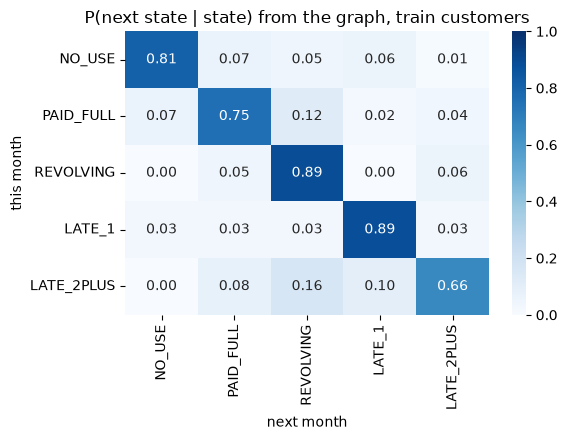

In [13]:
p1, p2 = GF.transition_probs(driver)
plt.figure(figsize=(6, 4.5)); sns.heatmap(p1, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("P(next state | state) from the graph, train customers"); plt.ylabel("this month"); plt.xlabel("next month")
plt.tight_layout(); plt.savefig(C.FIGURES / "graph_transition_network.png", dpi=120)

**Two-step view.** For each pair of consecutive states (e.g. REVOLVING then LATE_2PLUS), how often is the customer late in the month after? Also learned only from training customers.

In [14]:
pd.Series(p2, name="P(late next month)").sort_values(ascending=False).round(3).to_frame().head(12)

,P(late next month)
NO_USE|LATE_2PLUS,0.997
NO_USE|LATE_1,0.962
PAID_FULL|LATE_1,0.944
LATE_1|LATE_1,0.917
LATE_2PLUS|LATE_1,0.875
LATE_2PLUS|LATE_2PLUS,0.862
REVOLVING|LATE_1,0.833
REVOLVING|LATE_2PLUS,0.646
PAID_FULL|LATE_2PLUS,0.356
LATE_2PLUS|PAID_FULL,0.188


**Q11 · Scenario lens (hypothetical).** For a *hypothetical* increase of 30,000, compare the request with each customer's typical (median) monthly payment. `payback_months` = how many typical payments it would take to repay the full increase. This is not an observed request; notebook 08 builds on it.

In [15]:
q11 = G.run_file(driver, PQ / "Q11_request_vs_payment.cypher", increase=30000)
q11["payback_band"] = pd.cut(q11.payback_months, [0, 3, 6, 12, 36, np.inf], labels=["<=3", "3-6", "6-12", "12-36", ">36"])
q11["payback_band"] = q11.payback_band.cat.add_categories("no payments").fillna("no payments")
q11.payback_band.value_counts().sort_index().to_frame("customers")

,customers
payback_band,
<=3,1842
3-6,3913
6-12,5760
12-36,10284
>36,4463
no payments,3738


**Same request, different meaning.** Two real customers with the same credit limit but different typical payments get the same 30,000 request. For one it equals a couple of months of their usual payments; for the other, many months.

In [16]:
same = q11[(q11.credit_limit == 200000)]
a = same.iloc[(same.typical_payment - 20000).abs().argmin()]; b = same.iloc[(same.typical_payment - 10000).abs().argmin()]
pd.DataFrame([a, b], index=["Customer A", "Customer B"])[["customer_id", "credit_limit", "typical_payment", "increase_to_limit", "payback_months"]].round(2)

,customer_id,credit_limit,typical_payment,increase_to_limit,payback_months
Customer A,21092,200000.0,20643.0,0.15,1.45
Customer B,7208,200000.0,10000.0,0.15,3.00


**Extract the graph features.** The same pattern queries, with their thresholds lowered to 1, give a number per customer. We add the transition counts and the two population features computed from Q9 and the two-step table.

In [17]:
gfeat, p1, p2 = GF.extract(driver)
gfeat.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
customer_id,30000.0,15000.500,8660.398,1.000,7500.750,15000.500,22500.250,30000.000
g_max_late_streak,30000.0,0.795,1.513,0.000,0.000,0.000,1.000,6.000
g_late_onsets,30000.0,0.269,0.472,0.000,0.000,0.000,1.000,2.000
g_recoveries,30000.0,0.144,0.369,0.000,0.000,0.000,0.000,3.000
g_relapses,30000.0,0.036,0.187,0.000,0.000,0.000,0.000,2.000
g_latest_transition,30000.0,0.028,0.431,-1.000,0.000,0.000,0.000,1.000
g_max_util_rise_run,30000.0,0.680,0.890,0.000,0.000,0.000,1.000,5.000
g_weak_cov_after_late,30000.0,0.535,1.159,0.000,0.000,0.000,1.000,5.000
g_markov_next_late_prob,30000.0,0.251,0.332,0.036,0.071,0.071,0.094,0.962
g_path_typicality,30000.0,-0.619,0.538,-2.949,-0.994,-0.458,-0.118,-0.118


**Parity test.** We compute the same 9 features in plain pandas. Every value must match what Neo4j returned. This proves the Cypher logic is correct (and shows honestly that the graph organises the computation rather than creating new raw data).

In [18]:
wide_s = wide.merge(split)
pp1, pp2 = F.transition_tables(wide_s[wide_s.split == "train"])
pg = F.graph_features_pandas(wide_s, pp1, pp2).sort_values("customer_id", ignore_index=True)
mism = {c: int((~np.isclose(gfeat[c].astype(float), pg[c].astype(float))).sum()) for c in F.GRAPH_FEATURES}
assert np.allclose(p1, pp1) and all(v == 0 for v in mism.values()), mism
pd.Series(mism, name="mismatching customers").to_frame()

,mismatching customers
g_max_late_streak,0
g_late_onsets,0
g_recoveries,0
g_relapses,0
g_latest_transition,0
g_max_util_rise_run,0
g_weak_cov_after_late,0
g_markov_next_late_prob,0
g_path_typicality,0


**How new is this information?** For each graph feature: its strongest correlation with any baseline feature or raw column (close to 1 = mostly a repeat), and how well it separates defaulters on its own (training customers).

In [19]:
spec = pd.read_json(C.FEATURES / "feature_spec.json", typ="series")
base_cols = spec["raw_features"] + spec["engineered_features"]
tr = wide_s[wide_s.split == "train"].merge(pd.read_parquet(C.FEATURES / "baseline.parquet")).merge(gfeat)
rows = []
for g in F.GRAPH_FEATURES:
    c = tr[base_cols].corrwith(tr[g], method="spearman").abs()
    rows.append({"graph_feature": g, "closest_baseline_feature": c.idxmax(), "max_abs_spearman": round(c.max(), 2),
                 "single_feature_auc": round(S.single_feature_auc(tr[g], tr[C.TARGET]), 3)})
novelty = pd.DataFrame(rows).set_index("graph_feature"); novelty.to_csv(C.TABLES / "graph_feature_novelty.csv"); novelty

,closest_baseline_feature,max_abs_spearman,single_feature_auc
graph_feature,,,
g_max_late_streak,late_months,1.00,0.728
g_late_onsets,late_recent3,0.76,0.639
g_recoveries,max_status,0.53,0.549
g_relapses,late_months,0.31,0.535
g_latest_transition,status_m5,0.44,0.519
g_max_util_rise_run,util_slope,0.66,0.547
g_weak_cov_after_late,late_months,0.88,0.682
g_markov_next_late_prob,late_recent3,0.71,0.675
g_path_typicality,late_months,0.58,0.628


**Save** the graph features and the learned transition tables for the next notebooks.

In [20]:
gfeat.to_parquet(C.FEATURES / "graph.parquet", index=False)
p1.to_csv(C.TABLES / "transition_probabilities.csv")
pd.Series(p2, name="p_late_next").to_csv(C.TABLES / "two_step_late_probabilities.csv")
driver.close(); print(gfeat.shape)

(30000, 10)


### Takeaways
* Cypher finds concrete, explainable evidence per customer (month ranges, counts, relapse episodes) without ever seeing the label.
* Python validation confirms the patterns carry real risk information, and train and test agree.
* **Late streaks (Q2)** and **repeated lateness (Q1)** mark ~60% default rates (2.7× the base). **Relapse (Q10)** is almost as bad (~54%).
* **Rising utilization (Q4) is not a warning sign** (19%, below base), matching notebook 03.
* **Stable full payers (Q7)** have about half the base risk (12%).
* **Recovered customers (Q5)** sit at about the average rate (23%). That is better than repeat-late customers but still twice the ~11.5% of never-late customers: past lateness leaves a mark.
* The 9 graph features match pandas exactly. `g_max_late_streak` is practically a copy of `late_months` (ρ = 1.0), while `g_relapses`, `g_recoveries` and `g_latest_transition` are the most "new" but individually weak. Expect **a small gain at best** in notebook 07. That is a finding, not a failure.